# IKpy Quickstart #

Import the IKPy module : 

In [9]:
import ikpy.chain
import numpy as np
import ikpy.utils.plot as plot_utils


The basic element of IKPy is the kinematic `Chain`.
To create a chain from an URDF file : 

In [10]:
# will give warnings, that's OK
my_chain = ikpy.chain.Chain.from_urdf_file("./ur5/ur5_gripper.urdf")

/local/standlm/lab-2-ik/.pixi/envs/default/lib/python3.12/site-packages/ikpy/chain.py:60: UserWarning: Link Base link (index: 0) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive
  warnings.warn("Link {} (index: {}) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive".format(link.name, link_index))
/local/standlm/lab-2-ik/.pixi/envs/default/lib/python3.12/site-packages/ikpy/chain.py:60: UserWarning: Link ee_fixed_joint (index: 7) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive
  warnings.warn("Link {} (index: {}) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive".format(link.name, 

# Inverse kinematics

In Inverse Kinematics, you want the "end effector" of your robot to reach a specific 3D position (and in general, orientation) in space. The end effector is the final link of the robot arm, furthest from the base, and possibly a tool that is attached (a gripper in our robot model).

To have a more general representation of position, IKPy works with homogeneous coordinates. Homogenous coordinates are represented as a 4x4 matrix storing both position and orientation. Here we only consider (x,y,z) position, not orientation of the chain.

In [11]:
# define target X, Y, Z coordinate
target_position = [ 1.8, 1.0, 1.0]

In [12]:
# run inverse kinematics solver
print("The joint angles are : ", my_chain.inverse_kinematics(target_position))

The joint angles are :  [ 0.00000000e+00  3.61770912e-01 -4.20381159e-01 -2.98765080e-05
 -8.65432503e-01  1.36698319e+00  0.00000000e+00  0.00000000e+00]


You can check that the Inverse Kinematics is correct by comparing with the original position vector : 

In [13]:
# run forward kinematics on the inverse kinematics solution to verify
real_frame = my_chain.forward_kinematics(my_chain.inverse_kinematics(target_position))
print("Computed position vector : %s, goal position vector : %s" % (real_frame[:3, 3], target_position))

Computed position vector : [0.75941333 0.42189664 0.47343556], goal position vector : [1.8, 1.0, 1.0]


# Plotting
And finally plot the result : 

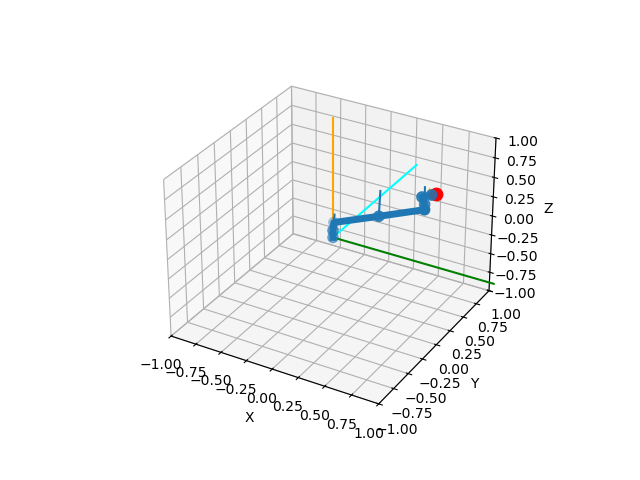

In [14]:
%matplotlib notebook
%matplotlib ipympl
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
fig, ax = plot_utils.init_3d_figure()

target_position = [ .7, .5, .5]

my_chain.plot(my_chain.inverse_kinematics(target_position), ax, target=target_position)


In [64]:
import random
import math
def randompoint(radius, center):
    x = random.gauss(0,1)
    y = random.gauss(0,1)
    z = random.gauss(0,1)

    point = np.array([x,y,z])
    norm = np.linalg.norm(point)
    

    return (point/norm * radius + center)

In [72]:
reachable_points = array [for i in range(30)] randompoint(3.5, 0)

SyntaxError: invalid syntax (1794983200.py, line 1)

In [66]:
reachable_points
points = np.asarray(reachable_points, dtype=float)


In [57]:
points

array([-2.3807055 , -0.12828506, -2.56237864])

In [58]:

# Actual end-effector positions recorded from forward kinematics.
points = np.asarray(reachable_points, dtype=float)

if points.ndim != 2 or points.shape[1] != 3:
  raise ValueError("reachable_points must contain [x, y, z] positions.")

points = np.unique(points, axis=0)

if len(points) < 4 or np.linalg.matrix_rank(points - points.mean(axis=0)) < 3:
  raise ValueError("Need at least four non-coplanar points for a 3D hull.")

hull = ConvexHull(points)

print("Actual reachable positions (meters):")
for point in points:
  print(f"[{point[0]:.6f}, {point[1]:.6f}, {point[2]:.6f}]")

print(f"\nConvex hull volume: {hull.volume:.6f} m³")
print(f"Convex hull surface area: {hull.area:.6f} m²")
print("Minimum x, y, z:", points.min(axis=0))
print("Maximum x, y, z:", points.max(axis=0))

np.savetxt(
  "reachable_points.csv",
  points,
  delimiter=",",
  header="x,y,z",
  comments="",
)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_trisurf(
  points[:, 0],
  points[:, 1],
  points[:, 2],
  triangles=hull.simplices,
  color="skyblue",
  edgecolor="gray",
  linewidth=0.4,
  alpha=0.35,
)
ax.scatter(
  points[:, 0], points[:, 1], points[:, 2],
  color="navy", s=10, label="Actual end-effector positions",
)

# Equal axis scales preserve the apparent shape.
center = (points.min(axis=0) + points.max(axis=0)) / 2
half_span = np.ptp(points, axis=0).max() / 2
ax.set_xlim(center[0] - half_span, center[0] + half_span)
ax.set_ylim(center[1] - half_span, center[1] + half_span)
ax.set_zlim(center[2] - half_span, center[2] + half_span)
ax.set_box_aspect((1, 1, 1))

ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")
ax.set_title("Estimated robot workspace boundary")
ax.legend()

plt.tight_layout()
plt.savefig("workspace_boundary.png", dpi=200)
plt.show()



ValueError: reachable_points must contain [x, y, z] positions.